##Part a

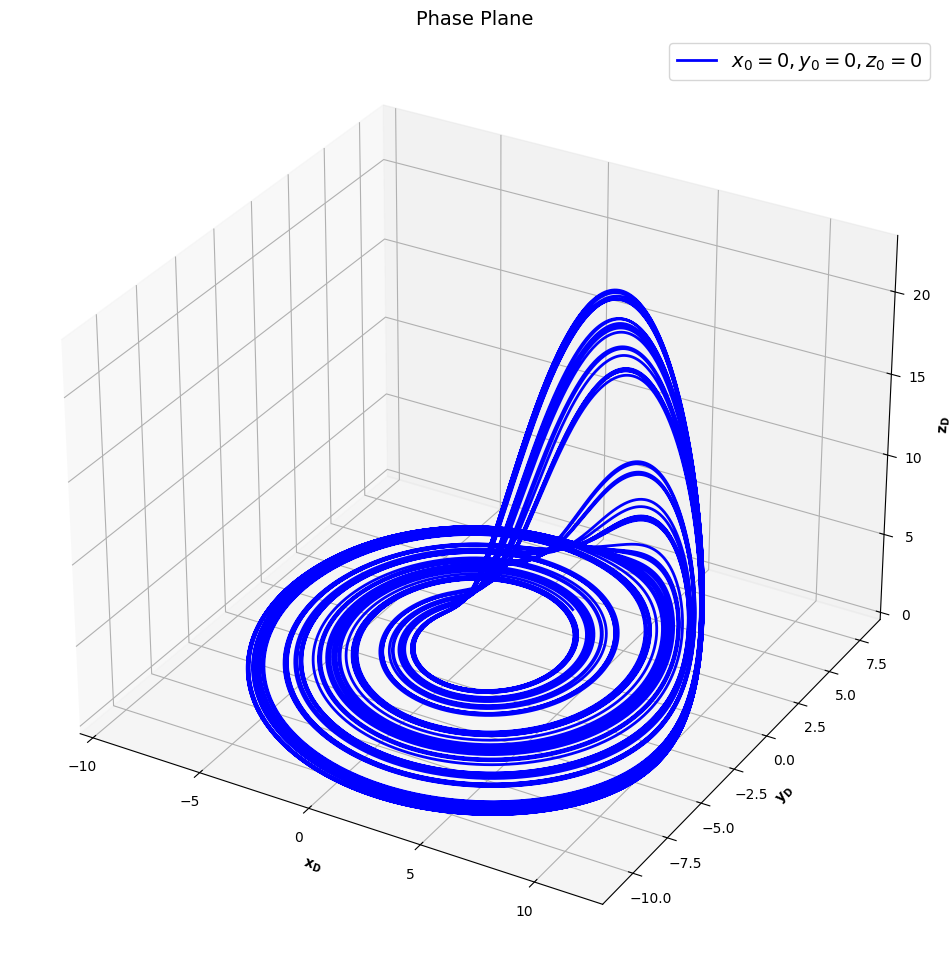

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#Help for solving the IVP came from https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html
#Help for 3D plotting is from https://matplotlib.org/stable/gallery/mplot3d/2dcollections3d.html

# Define the "driver" Rössler chaotic system
def driver_rossler_system(t, w_D, a, b, c):
    x_D, y_D, z_D = w_D
    return [-y_D - z_D, x_D + a * y_D, b + z_D * (x_D - c)]

#Define time interval using np.linspace
t = np.linspace(0, 500, 100000)

# Initial conditions are [x(0), y(0)], z(0)] = [0, 0, 0] with a = 0.2, b = 0.2 and c = 5.7
sol = solve_ivp(driver_rossler_system, [0, 500], [0, 0, 0], args=(0.2, 0.2, 5.7), t_eval=t)

#Drop transient time, which given t=500 seconds, we will assume to be t≤50
non_transient = sol.t > 50
x_D_func, y_D_func, z_D_func = sol.y[:, non_transient]

#Initialize 3D figure and axis object
fig = plt.figure(figsize=(12, 30))
ax = fig.add_subplot(projection='3d')

# Plot the state trajectory
ax.plot(x_D_func, y_D_func, z_D_func, color='b', linewidth=2, label=f'$x_0=0, y_0=0, z_0=0$')

# Plot everything + make labels
ax.set_title('Phase Plane', fontsize=14)
ax.set_xlabel(r'$\mathbf{x_D}$')
ax.set_ylabel(r'$\mathbf{y_D}$')
ax.set_zlabel(r'$\mathbf{z_D}$')
ax.tick_params(axis='both', which='major', labelsize=10)
ax.legend(fontsize=14)

plt.show()

##Part d

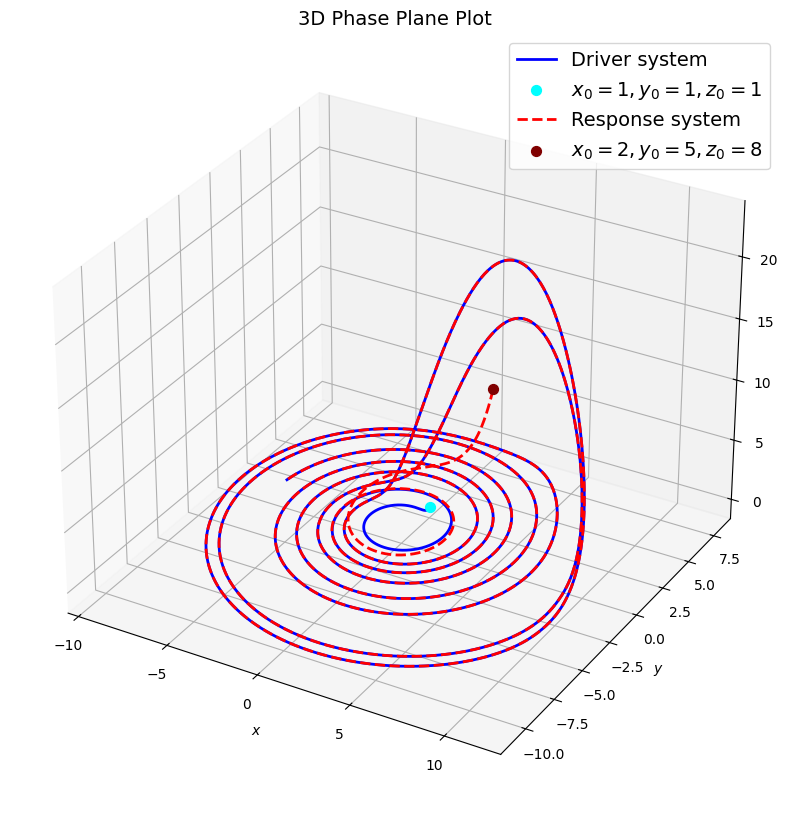

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#Help for solving the IVP came from https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html
#Help for 3D plotting is from https://matplotlib.org/stable/gallery/mplot3d/2dcollections3d.html

# Define the "driver" and "response" Rössler chaotic system together
def driver_and_response_rossler_system(t, w, a, b, c):
    x_D, y_D, z_D, x_R, y_R, z_R = w
    #Define "control functions" we created in part c
    u_1 = (z_R - z_D) - (x_R - x_D)
    u_2 = -2 * a * (y_R - y_D)
    u_3 = (x_D * z_D) - (x_R * z_R)
    return [-y_D - z_D, x_D + a * y_D, b + z_D * (x_D - c),
    -y_R - z_R + u_1, x_R + a * y_R + u_2, b + z_R * (x_R - c) + u_3]

#Define time interval using np.linspace
t = np.linspace(0, 50, 10000)

# Initial conditions are
# [x_D(0), y_D(0)], z_D(0), x_R(0), y_R(0), z_R(0)] = [1, 1, 1, 2, 5, 8]
# with a = 0.2, b = 0.2 and c = 5.7
sol = solve_ivp(driver_and_response_rossler_system, [0, 50], [1, 1, 1, 2, 5, 8], args=(0.2, 0.2, 5.7), t_eval=t)
x_D_func, y_D_func, z_D_func, x_R_func, y_R_func, z_R_func = sol.y

#Initialize 3D figure and axis object
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(projection='3d')

# Plot the state trajectory for driver
ax.plot(x_D_func, y_D_func, z_D_func, color='b', linewidth=2, label='Driver system')

#Plot the initial condition for driver system
ax.scatter(1, 1, 1, color='cyan', s=50, label=f'$x_0=1, y_0=1, z_0=1$')

# Plot the state trajectory for "response"
ax.plot(x_R_func, y_R_func, z_R_func, color='red', linewidth=2, ls = '--', label='Response system')

#Plot the initial condition for response system
ax.scatter(2, 5, 8, color='maroon', s=50, label=f'$x_0=2, y_0=5, z_0=8$')

# Plot everything + make labels
ax.set_title('3D Phase Plane Plot', fontsize=14)
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$y$')
ax.set_zlabel(r'$z$')
ax.tick_params(axis='both', which='major', labelsize=10)
ax.legend(fontsize=14)

plt.show()

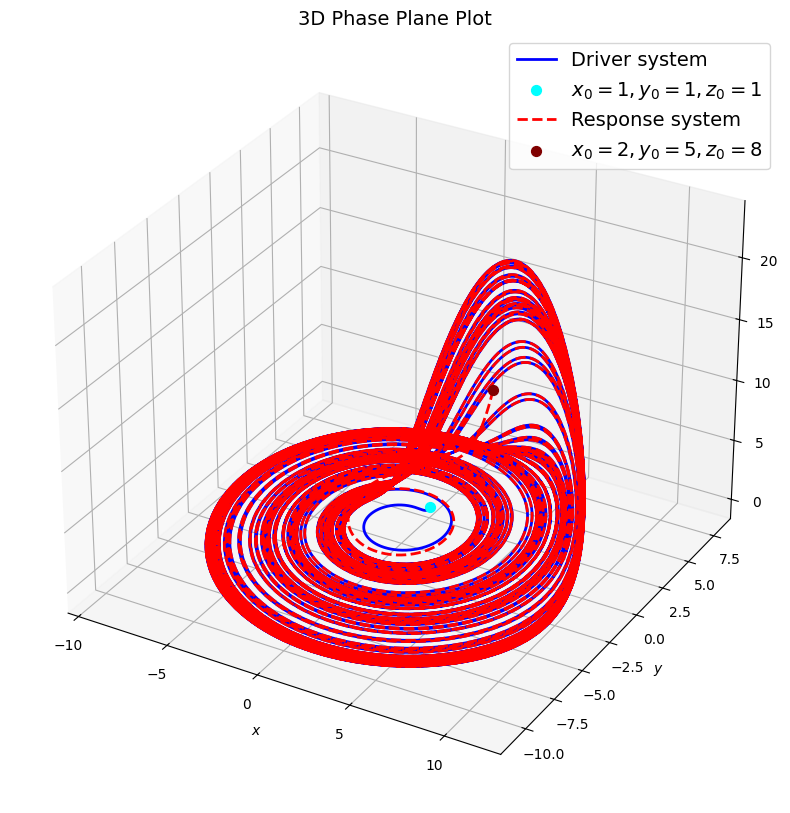

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#Help for solving the IVP came from https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html
#Help for 3D plotting is from https://matplotlib.org/stable/gallery/mplot3d/2dcollections3d.html

# Define the "driver" and "response" Rössler chaotic system together
def driver_and_response_rossler_system(t, w, a, b, c):
    x_D, y_D, z_D, x_R, y_R, z_R = w
    #Define "control functions" we created in part c
    u_1 = (z_R - z_D) - (x_R - x_D)
    u_2 = -2 * a * (y_R - y_D)
    u_3 = (x_D * z_D) - (x_R * z_R)
    return [-y_D - z_D, x_D + a * y_D, b + z_D * (x_D - c),
    -y_R - z_R + u_1, x_R + a * y_R + u_2, b + z_R * (x_R - c) + u_3]

#Define time interval using np.linspace
t = np.linspace(0, 500, 100000)

# Initial conditions are
# [x_D(0), y_D(0)], z_D(0), x_R(0), y_R(0), z_R(0)] = [1, 1, 1, 2, 5, 8]
# with a = 0.2, b = 0.2 and c = 5.7
sol = solve_ivp(driver_and_response_rossler_system, [0, 500], [1, 1, 1, 2, 5, 8], args=(0.2, 0.2, 5.7), t_eval=t)
x_D_func, y_D_func, z_D_func, x_R_func, y_R_func, z_R_func = sol.y

#Initialize 3D figure and axis object
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(projection='3d')

# Plot the state trajectory for driver
ax.plot(x_D_func, y_D_func, z_D_func, color='b', linewidth=2, label='Driver system')

#Plot the initial condition for driver system
ax.scatter(1, 1, 1, color='cyan', s=50, label=f'$x_0=1, y_0=1, z_0=1$')

# Plot the state trajectory for "response"
ax.plot(x_R_func, y_R_func, z_R_func, color='red', linewidth=2, ls = '--', label='Response system')

#Plot the initial condition for response system
ax.scatter(2, 5, 8, color='maroon', s=50, label=f'$x_0=2, y_0=5, z_0=8$')

# Plot everything + make labels
ax.set_title('3D Phase Plane Plot', fontsize=14)
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$y$')
ax.set_zlabel(r'$z$')
ax.tick_params(axis='both', which='major', labelsize=10)
ax.legend(fontsize=14)

plt.show()

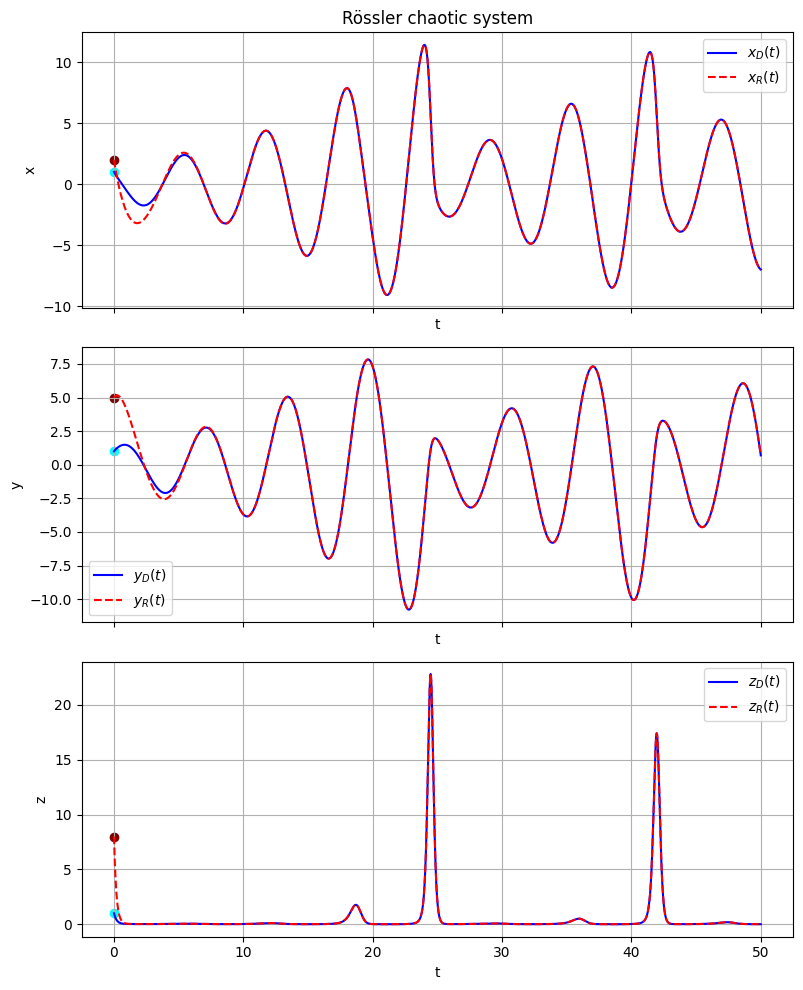

In [34]:
# Create three separate subplots
fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# Plot x(t)
axs[0].plot(t, x_D_func, color='b', label=f'$x_D(t)$')
axs[0].plot(t, x_R_func, color='r', linestyle = '--', label=f'$x_R(t)$')
axs[0].scatter(0, 1, color='cyan')
axs[0].scatter(0, 2, color='maroon')
axs[0].set_ylabel('x')
axs[0].set_xlabel('t')
axs[0].set_title('Rössler chaotic system')
axs[0].legend()
axs[0].grid(True)

# Plot y(t)
axs[1].plot(t, y_D_func, color='b', label=f'$y_D(t)$')
axs[1].plot(t, y_R_func, color='r', linestyle = '--', label=f'$y_R(t)$')
axs[1].scatter(0, 1, color='cyan')
axs[1].scatter(0, 5, color='maroon')
axs[1].set_ylabel('y')
axs[1].set_xlabel('t')
axs[1].legend()
axs[1].grid(True)

# Plot z(t)
axs[2].plot(t, z_D_func, color='b', label=f'$z_D(t)$')
axs[2].plot(t, z_R_func, color='r', linestyle = '--', label=f'$z_R(t)$')
axs[2].scatter(0, 1, color='cyan')
axs[2].scatter(0, 8, color='maroon')
axs[2].set_ylabel('z')
axs[2].set_xlabel('t')
axs[2].legend()
axs[2].grid(True)

plt.tight_layout()
plt.show()